In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification

In [2]:
X, y = make_classification(
    n_samples=200,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=2.5,
    random_state=42
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (200, 2)
Target shape: (200,)


## Visualize the Dataset

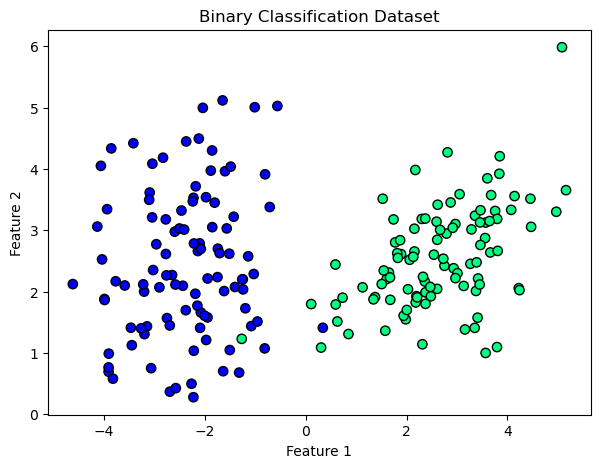

In [3]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap='winter',
    s=45,
    edgecolors='black'
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Binary Classification Dataset")

plt.show()

## Step 3: Build the Perceptron Class

Before writing the training loop, let's understand what our model needs.

Our perceptron requires five components:

Weight initialization.
Bias initialization.
Activation function.
Prediction mechanism.
Weight update mechanism.

We'll combine these into a Python class.

3.1 Initialize the Perceptron

In [15]:
class Perceptron:
    def __init__(self, learning_rate,epochs):
        self.lr = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = None

        self.errors = []

    # Initialize Weights and Bias
    def initialize_parameters(self, n_features):

        self.weights = np.zeros(n_features)
        self.bias = 0

    # Create activation function
    def activation(self,z):
        return 1 if z > 0 else 0

    # Create the prediction functioni
    def predict_single(self, x):
        z = np.dot(x, self.weights) + self.bias
        return self.activation(z)

    # Prepare the training model
    def fit(self, X, y):

        n_samples, n_features = X.shape
        self.initialize_parameters(n_features)
        
        for epoch in range(self.epochs):
            errors = 0
            indices = np.random.permutation(n_samples)
    
            for idx in indices:
                x_i = X[idx]
                y_actual = y[idx]
                y_pred = self.predict_single(x_i)
                error = y_actual - y_pred
                
                if error != 0:
                    self.weights += self.lr * error * x_i
                    self.bias += self.lr * error
                    errors += 1
    
            self.errors.append(errors)
    
            if errors == 0:
                print(f"Converged at epoch {epoch + 1}")
                break
    
        return self

    def predict(self, X):
        return np.array([self.predict_single(x)for x in X])

### 3.2 

## Train the model

In [16]:
model = Perceptron(
    learning_rate=0.01,
    epochs=100
)

In [17]:
model.fit(X,y)

In [18]:
# Inspect the learned parameters
print("Learned Weights:", model.weights)
print("Learned Bias:", model.bias)
print("Total Epochs:", len(model.errors))

Learned Weights: [ 0.06804465 -0.0205422 ]
Learned Bias: 0.060000000000000005
Total Epochs: 100


In [21]:
model.errors

[7,
 2,
 2,
 4,
 2,
 5,
 4,
 4,
 7,
 2,
 2,
 4,
 2,
 4,
 4,
 2,
 5,
 3,
 4,
 4,
 2,
 4,
 4,
 3,
 5,
 3,
 3,
 4,
 5,
 3,
 4,
 4,
 4,
 4,
 3,
 3,
 4,
 3,
 3,
 3,
 4,
 2,
 4,
 4,
 4,
 4,
 2,
 3,
 7,
 4,
 4,
 2,
 5,
 3,
 4,
 2,
 3,
 5,
 3,
 2,
 4,
 4,
 6,
 2,
 4,
 4,
 2,
 2,
 4,
 4,
 4,
 5,
 2,
 5,
 4,
 5,
 4,
 3,
 4,
 3,
 3,
 4,
 4,
 2,
 5,
 4,
 2,
 4,
 4,
 3,
 3,
 3,
 3,
 5,
 3,
 2,
 3,
 4,
 3,
 4]

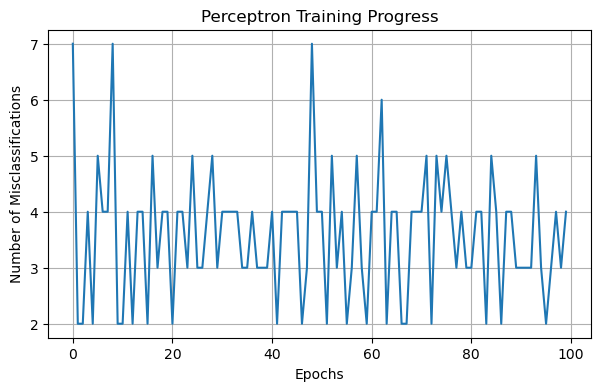

In [22]:
plt.figure(figsize=(7, 4))

plt.plot(model.errors)

plt.xlabel("Epochs")
plt.ylabel("Number of Misclassifications")
plt.title("Perceptron Training Progress")

plt.grid()
plt.show()

## Generate predictions

In [23]:
y_pred = model.predict(X)

print("Actual:", y)
print("Predicted:", y_pred)

Actual: [1 1 1 1 1 0 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 0 1 0 0 1 1 1 0 1 0 1 0 1 1 0 0
 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 1 1
 1 0 1 1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 1 1 1 0 1 0 0 0 0 0 0 1 1 0 1
 1 1 0 1 1 1 0 1 1 1 1 0 0 1 0 1 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 1 0 0 1
 1 1 1 1 0 1 1 1 1 0 1 0 0 0 0 1 1 1 0 1 1 1 0 1 1 0 0 1 0 1 1 1 1 1 0 1 1
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0]
Predicted: [1 1 1 1 1 0 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 0 1 0 0 1 1 1 0 1 0 1 0 1 1 0 0
 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 1 1
 1 0 1 1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 1 1 1 0 1 0 0 0 0 0 0 1 1 1 1
 1 1 0 1 1 1 0 1 1 1 1 0 0 1 0 0 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 1 0 0 1
 1 1 1 1 0 1 1 1 1 0 1 0 0 0 0 1 1 1 0 1 1 1 0 1 1 0 0 1 0 1 1 1 1 1 0 1 1
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0]


## Evaluate model performance

In [24]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred))

print("\nClassification Report:")
print(classification_report(y, y_pred))

Accuracy: 0.99

Confusion Matrix:
[[99  1]
 [ 1 99]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       100
           1       0.99      0.99      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



## Calculate the decision boundary

In [25]:
# Extract learned parameters
w1, w2 = model.weights
b = model.bias

# Generate x-axis values
x_values = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)

# Calculate corresponding y-axis values
y_values = -(w1 * x_values + b) / w2

## Plot the findings

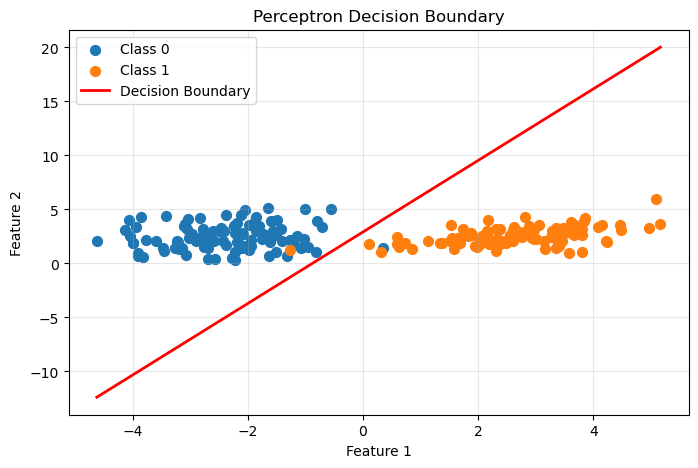

In [26]:
plt.figure(figsize=(8, 5))

# Plot class 0
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0",
    s=50
)

# Plot class 1
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1",
    s=50
)

# Plot decision boundary
plt.plot(
    x_values,
    y_values,
    color="red",
    linewidth=2,
    label="Decision Boundary"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Perceptron Decision Boundary")

plt.legend()
plt.grid(alpha=0.3)
plt.show()